In [1]:

from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.inspection import permutation_importance

ROOT = Path.cwd()
OUT = ROOT / "outputs"
OUT3 = ROOT / "outputs"/"output_03"
FIG = OUT / "figures"

OUT3.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

config = json.loads(
    (OUT / "config.json").read_text(encoding="utf-8")
)

STATES = config["model_states"]
CROPS = config["crops"]
FEATURES = config["features"]

train = pd.read_csv(
    OUT / "train.csv",
    dtype={"Outlier_Flag": "boolean"}
)

val = pd.read_csv(
    OUT / "validation.csv",
    dtype={"Outlier_Flag": "boolean"}
)

test = pd.read_csv(
    OUT / "test.csv",
    dtype={"Outlier_Flag": "boolean"}
)
#chuan bi tap de fit lai sau khi chon mo hinh
KEY = [
    "State_Name",
    "District_ID",
    "Crop_Year",
    "Season",
    "Crop"
]
#chi dung đe fit lai sau khi da chon bang validation
dev = (
    pd.concat([train, val], ignore_index=True)
    .sort_values(KEY)
    .reset_index(drop=True)
)

dev = dev.sort_values(KEY).reset_index(drop=True)

scale_train = train.groupby("Crop")["Yield"].median()
scale_dev = dev.groupby("Crop")["Yield"].median()

In [2]:
FEATURES = [
    "Year_Index",
    "State_Name",
    "District_ID",
    "Crop",
    "Season"
]

# Nếu các cell khác dùng feature_cols thì giữ cùng danh sách.
feature_cols = FEATURES
target_col = "Yield"

# Chuẩn bị dữ liệu cho mô hình.
X_train = train[feature_cols]
y_train = train[target_col]

X_val = val[feature_cols]
y_val = val[target_col]

X_test = test[feature_cols]
y_test = test[target_col]

In [3]:

def fit_linear(data):
    """
    Học phương trình:
        Yield = intercept + slope * Year_Index

    Ưu tiên nhóm bang–cây–mùa.
    Nếu nhóm thiếu dữ liệu, dùng bang–cây hoặc cây.
    """
    equations = {}

    levels = [
        ["Crop"],
        ["State_Name", "Crop"],
        ["State_Name", "Crop", "Season"]
    ]

    for columns in levels:
        for name, group in data.groupby(columns):

            if not isinstance(name, tuple):
                name = (name,)

            # Tính năng suất trung bình mỗi năm trong nhóm.
            yearly = (
                group.groupby("Crop_Year")["Yield"]
                .mean()
            )

            # Cần ít nhất 3 năm cho baseline minh họa.
            if len(yearly) < 3:
                continue

            reg = stats.linregress(
                yearly.index.to_numpy() - 1998,
                yearly.to_numpy()
            )

            if len(columns) == 1:
                key = ("ALL", name[0], "ALL")

            elif len(columns) == 2:
                key = (name[0], name[1], "ALL")

            else:
                key = name

            equations[key] = (
                reg.intercept,
                reg.slope
            )

    return equations


def predict_linear(equations, data):
    """Dự đoán bằng phương trình đã học."""
    predictions = []

    for row in data.itertuples(index=False):

        possible_keys = [
            (row.State_Name, row.Crop, row.Season),
            (row.State_Name, row.Crop, "ALL"),
            ("ALL", row.Crop, "ALL")
        ]

        found = False

        for key in possible_keys:
            if key in equations:
                intercept, slope = equations[key]

                predicted_yield = (
                    intercept + slope * row.Year_Index
                )

                # Năng suất dự đoán không được âm.
                predictions.append(
                    max(0, predicted_yield)
                )

                found = True
                break

        if not found:
            raise ValueError(
                f"Cây {row.Crop} chưa đủ số năm "
                "để xây dựng baseline."
            )

    return np.array(predictions)


# 4. MÔ HÌNH RIDGE và RANDOM FOREST

def make_model(name, parameter):
    """
    Pipeline gồm:
    1. Chuẩn hóa Year_Index.
    2. Mã hóa các cột phân loại.
    3. Huấn luyện mô hình.
    """

    processor = ColumnTransformer([
        (
            "year",
            StandardScaler(),
            ["Year_Index"]
        ),
        (
            "category",
            OneHotEncoder(handle_unknown="ignore"),
            ["State_Name", "District_ID", "Crop", "Season"]
        )
    ])

    if name == "Ridge":
        estimator = Ridge(
            alpha=parameter,
            solver="lsqr"
        )

    elif name == "Random Forest":
        estimator = RandomForestRegressor(
            n_estimators=100,
            max_depth=18,
            min_samples_leaf=int(parameter),
            max_features=0.7,
            random_state=42,
            n_jobs=2
        )

    else:
        raise ValueError(
            f"Tên mô hình không hợp lệ: {name}"
        )

    # Bộ mã hóa và chuẩn hóa chỉ học khi gọi fit.
    return Pipeline([
        ("prepare", processor),
        ("model", estimator)
    ])

# 5. HÀM ĐÁNH GIÁ


def evaluate(data, prediction, scales):
    """
    MAE, RMSE: cùng đơn vị với Yield.
    R2: mức độ giải thích biến thiên.

    Macro_NMAE:
    - Chia sai số tuyệt đối cho median Yield của từng cây.
    - Tính trung bình riêng từng cây.
    - Sau đó lấy trung bình giữa các cây.
    """
    prediction = np.asarray(prediction)

    actual = data["Yield"].to_numpy()

    absolute_error = np.abs(
        actual - prediction
    )

    normalized = pd.DataFrame({
        "Crop": data["Crop"].to_numpy(),
        "Error": (
            absolute_error
            / data["Crop"].map(scales).to_numpy()
        )
    })

    # R2 không có ý nghĩa khi nhóm chỉ có một bản ghi.
    if len(data) >= 2:
        r2 = r2_score(actual, prediction)
    else:
        r2 = np.nan

    return {
        "MAE": mean_absolute_error(actual, prediction),

        "RMSE": np.sqrt(
            mean_squared_error(actual, prediction)
        ),

        "R2": r2,

        "Macro_NMAE": (
            normalized.groupby("Crop")["Error"]
            .mean()
            .mean()
        )
    }

In [4]:
# 6. HUẤN LUYỆN VÀ CHỌN BẰNG VALIDATION

vp = val.copy()

# Baseline chỉ học từ train.
eq_train = fit_linear(train)

vp["Linear Year"] = predict_linear(
    eq_train,
    val
)

validation_rows = [{
    "Model": "Linear Year",
    "Parameter": 0,
    **evaluate(
        val,
        vp["Linear Year"],
        scale_train
    )
}]

candidates = {}

# Thử một số cấu hình nhỏ, phù hợp bài tập sinh viên.
settings = [
    ("Ridge", [0.1, 1, 10]),
    ("Random Forest", [5, 15])
]

for name, parameters in settings:
    for parameter in parameters:

        print("Đang huấn luyện:", name, parameter)

        model = make_model(name, parameter)

        model.fit(
            train[FEATURES],
            train["Yield"]
        )

        prediction = np.maximum(
            0,
            model.predict(val[FEATURES])
        )

        validation_rows.append({
            "Model": name,
            "Parameter": parameter,
            **evaluate(
                val,
                prediction,
                scale_train
            )
        })

        candidates[(name, parameter)] = model


validation = pd.DataFrame(validation_rows)

validation.to_csv(
    OUT3 / "validation_metrics.csv",
    index=False
)

# Tiêu chí được chọn trước khi xem test:
# Macro_NMAE thấp nhất.
selected = (
    validation.sort_values("Macro_NMAE")
    .iloc[0]["Model"]
)

best_parameters = {}

# Lưu cấu hình tốt nhất của mỗi mô hình.
for name in ["Ridge", "Random Forest"]:

    best = (
        validation[validation["Model"] == name]
        .sort_values("Macro_NMAE")
        .iloc[0]
    )

    parameter = float(best["Parameter"])
    best_parameters[name] = parameter

    vp[name] = np.maximum(
        0,
        candidates[(name, parameter)].predict(
            val[FEATURES]
        )
    )

vp.to_csv(
    OUT3 / "validation_predictions.csv",
    index=False
)

print("\nKết quả validation:")
print(validation.round(4).to_string(index=False))

print("\nMô hình được chọn:", selected)

# 7. FIT LẠI TRÊN TRAIN + VALIDATION
eq_dev = fit_linear(dev)

predictions = test.copy()

predictions["Linear Year"] = predict_linear(
    eq_dev,
    test
)

models = {}

for name, parameter in best_parameters.items():

    print("Đang fit lại:", name)

    model = make_model(name, parameter)

    model.fit(
        dev[FEATURES],
        dev["Yield"]
    )

    models[name] = model

    predictions[name] = np.maximum(
        0,
        model.predict(test[FEATURES])
    )

# 8. ĐÁNH GIÁ TEST
model_names = [
    "Linear Year",
    "Ridge",
    "Random Forest"
]

metrics = pd.DataFrame([
    {
        "Model": name,
        **evaluate(
            test,
            predictions[name],
            scale_dev
        )
    }
    for name in model_names
])

metrics.to_csv(
    OUT3 / "test_metrics.csv",
    index=False
)

predictions.to_csv(
    OUT3 / "test_predictions.csv",
    index=False
)

print("\nKết quả test:")
print(metrics.round(4).to_string(index=False))


# Đánh giá riêng theo cây và theo bang.
for column, filename in [
    ("Crop", "metrics_by_crop.csv"),
    ("State_Name", "metrics_by_state.csv")
]:

    detail_rows = []

    for model_name in model_names:
        for group_name, group in predictions.groupby(column):

            detail_rows.append({
                "Model": model_name,
                column: group_name,
                "N": len(group),
                **evaluate(
                    group,
                    group[model_name],
                    scale_dev
                )
            })

    pd.DataFrame(detail_rows).to_csv(
        OUT3 / filename,
        index=False
    )

# Test 2013 và 2014 đều được dự đoán bằng mô hình
# chỉ học dữ liệu đến hết năm 2012.

Đang huấn luyện: Ridge 0.1
Đang huấn luyện: Ridge 1


Đang huấn luyện: Ridge 10
Đang huấn luyện: Random Forest 5


Đang huấn luyện: Random Forest 15



Kết quả validation:
        Model  Parameter    MAE    RMSE     R2  Macro_NMAE
  Linear Year        0.0 2.0252 10.5185 0.6433      0.3852
        Ridge        0.1 3.1656  7.4220 0.8224      2.0235
        Ridge        1.0 3.1640  7.4197 0.8225      2.0223
        Ridge       10.0 3.1498  7.3996 0.8235      2.0135
Random Forest        5.0 1.0904  4.2411 0.9420      0.3366
Random Forest       15.0 1.3101  4.9562 0.9208      0.3759

Mô hình được chọn: Random Forest


Đang fit lại: Ridge
Đang fit lại: Random Forest



Kết quả test:
        Model    MAE   RMSE     R2  Macro_NMAE
  Linear Year 1.6647 8.2689 0.7894      0.3656
        Ridge 2.7522 6.7809 0.8584      1.7499
Random Forest 1.0820 4.1462 0.9470      0.3429


In [5]:
# 9. ĐÁNH GIÁ NHÓM NĂNG SUẤT THẤP
# Q10 của từng cây được tính từ dữ liệu đến năm 2012.
# Đây là nhóm năng suất thấp theo lịch sử,
# không khẳng định là mất mùa.
low_threshold = (
    dev.groupby("Crop")["Yield"]
    .quantile(0.1)
)

low = predictions[
    predictions["Yield"]
    <= predictions["Crop"].map(low_threshold)
].copy()

low_rows = []

for name in model_names:
    for crop, group in low.groupby("Crop"):

        low_rows.append({
            "Model": name,
            "Crop": crop,
            "N": len(group),

            "MAE": mean_absolute_error(
                group["Yield"],
                group[name]
            ),

            "Mean_Overprediction": (
                group[name] - group["Yield"]
            ).mean()
        })

low_metrics = pd.DataFrame(
    low_rows,
    columns=[
        "Model",
        "Crop",
        "N",
        "MAE",
        "Mean_Overprediction"
    ]
)

low_metrics.to_csv(
    OUT3 / "low_yield_metrics.csv",
    index=False
)

print("\nĐánh giá các vụ năng suất thấp:")
print(low_metrics.round(4).to_string(index=False))

# Mean_Overprediction > 0:
# trung bình mô hình dự đoán cao hơn năng suất thực tế.


# 10. DIỄN GIẢI RANDOM FOREST

# Hoán vị từng đặc trưng rồi đo MAE tăng thêm.
# Đặc trưng bị đảo mà MAE tăng mạnh:
# mô hình phụ thuộc nhiều vào đặc trưng đó.
result = permutation_importance(
    models["Random Forest"],
    test[FEATURES],
    test["Yield"],
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
    n_jobs=1
)

importance = pd.DataFrame({
    "Feature": FEATURES,
    "Importance": result.importances_mean,
    "SD": result.importances_std
}).sort_values("Importance")

importance.to_csv(
    OUT3 / "importance.csv",
    index=False
)

print("\nPermutation importance của Random Forest:")
print(importance.round(4).to_string(index=False))


Đánh giá các vụ năng suất thấp:
        Model              Crop  N     MAE  Mean_Overprediction
  Linear Year         Arhar/Tur 45  0.4319               0.4319
  Linear Year              Gram 84  0.7443               0.7443
  Linear Year         Groundnut 32  0.4252               0.4252
  Linear Year             Jowar 26  0.6688               0.6688
  Linear Year             Maize 80  1.0893               1.0893
  Linear Year Moong(Green Gram) 29  0.1811               0.1811
  Linear Year Rapeseed &Mustard 30  0.2329               0.2329
  Linear Year              Rice 32  0.5741               0.4613
  Linear Year           Sesamum 43  0.1428               0.1428
  Linear Year         Sugarcane 10 15.8529              15.8529
  Linear Year              Urad 35  0.2332               0.2332
  Linear Year             Wheat 31  0.9535               0.9535
        Ridge         Arhar/Tur 45  0.6717               0.2740
        Ridge              Gram 84  0.3913              -0.2761
       


Permutation importance của Random Forest:
    Feature  Importance     SD
 Year_Index      0.0000 0.0000
District_ID      0.1140 0.0028
     Season      1.6151 0.1724
 State_Name      2.6078 0.1390
       Crop      8.0318 0.0781


In [6]:
# 11. SAI SỐ VALIDATION ĐỂ THAM KHẢO ĐỘ TIN CẬY

vp["AbsError"] = np.abs(
    vp["Yield"] - vp[selected]
)

# Độ tin cậy này ở cấp bang–cây–mùa,
# không phải sai số được xác nhận riêng từng huyện.
reliability = vp.groupby(
    ["State_Name", "Crop", "Season"]
).agg(
    Validation_MAE=("AbsError", "mean"),
    Validation_N=("AbsError", "size")
).reset_index()

reliability["Validation_NMAE"] = (
    reliability["Validation_MAE"]
    / reliability["Crop"].map(scale_train)
)


# 12. TỔNG HỢP LỊCH SỬ HUYỆN–CÂY–MÙA

# Whole Year không phải một thời vụ gieo cụ thể.
seasonal = dev[
    dev["Season"] != "Whole Year"
].copy()

if seasonal.empty:
    raise ValueError(
        "Không có dữ liệu mùa cụ thể để tạo đề xuất."
    )

history_rows = []

groups = seasonal.groupby(
    ["State_Name", "District_ID", "Crop", "Season"]
)

for (state, district, crop, season), group in groups:

    recent = group[
        group["Crop_Year"].between(2008, 2012)
    ]

    slope = np.nan

    # Chỉ tính xu hướng gần đây khi có ít nhất 3 năm.
    if recent["Crop_Year"].nunique() >= 3:
        slope = stats.linregress(
            recent["Crop_Year"],
            recent["Yield"]
        ).slope

    mean_yield = group["Yield"].mean()

    # CV: mức dao động tương đối của năng suất.
    if mean_yield > 0:
        cv = (
            100 * group["Yield"].std()
            / mean_yield
        )
    else:
        cv = np.nan

    history_rows.append({
        "State_Name": state,
        "District_ID": district,
        "District_Name": group["District_Name"].iloc[0],
        "Crop": crop,
        "Season": season,

        "Years": group["Crop_Year"].nunique(),
        "Last_Year": group["Crop_Year"].max(),

        "Mean_Yield": mean_yield,
        "CV": cv,

        "Recent_Years": recent["Crop_Year"].nunique(),
        "Recent_Trend": slope
    })

history = pd.DataFrame(history_rows)

history.to_csv(
    OUT3 / "history_for_recommendations.csv",
    index=False
)

# Gắn sai số validation vào nhóm tương ứng.
rec = history.merge(
    reliability,
    on=["State_Name", "Crop", "Season"],
    how="left",
    validate="many_to_one"
)

# 13. DỰ ĐOÁN HỒI CỨU CHO NĂM 2014

# Mô hình học đến năm 2012.
# Đây là minh họa dự báo lịch sử, không phải dự báo năm 2026.
rec["Prediction_Year"] = 2014
rec["Year_Index"] = 2014 - 1998

if selected == "Linear Year":

    rec["Predicted_Yield"] = predict_linear(
        eq_dev,
        rec
    )

else:

    rec["Predicted_Yield"] = np.maximum(
        0,
        models[selected].predict(rec[FEATURES])
    )

In [7]:

# 14. PHÂN LOẠI ĐỀ XUẤT


def format_number(value, digits=3):
    """Hiển thị số; nếu thiếu thì ghi rõ thiếu dữ liệu."""
    if pd.isna(value):
        return "chưa đủ dữ liệu"

    return f"{value:.{digits}f}"


# Quy tắc minh họa do nhóm đặt trước khi xem test, không phải ngưỡng đã học từ dữ liệu.
THRESHOLDS = {
    "min_years": 8, "min_recent_years": 3, "last_year": 2012, "min_validation_n": 10,
    "recommended_years": 10, "recommended_cv": 25, "caution_cv": 40,
    "recommended_nmae": 0.3, "caution_nmae": 0.5, "decline_percent": -2
}
threshold_reasons = {
    "min_years": "Yêu cầu nhiều năm lịch sử để giảm kết luận từ chuỗi quá ngắn.",
    "min_recent_years": "Ít nhất 3 năm gần đây để tính xu hướng có hơn 2 điểm.",
    "last_year": "Yêu cầu có dữ liệu đến cuối giai đoạn phát triển mô hình.",
    "min_validation_n": "Yêu cầu tối thiểu số quan sát cho sai số cấp bang–cây–mùa.",
    "recommended_years": "Mức ưu tiên đòi hỏi chuỗi lịch sử dài hơn mức tối thiểu.",
    "recommended_cv": "Quy ước mức ưu tiên: SD không quá 25% năng suất trung bình.",
    "caution_cv": "Quy ước cảnh báo khi SD vượt 40% năng suất trung bình.",
    "recommended_nmae": "MAE không quá 30% median năng suất cây trên train.",
    "caution_nmae": "Cảnh báo khi MAE vượt 50% median năng suất cây trên train.",
    "decline_percent": "Cảnh báo khi slope/mean thấp hơn −2% mỗi năm; đây là tỷ lệ xấp xỉ."
}
threshold_table = pd.DataFrame([
    {"Rule": key, "Value": value, "Rationale": threshold_reasons[key],
     "Source": "Quy ước minh họa của nhóm; chưa có căn cứ xác nhận là ngưỡng tối ưu"}
    for key, value in THRESHOLDS.items()
])
threshold_table.to_csv(OUT3 / "recommendation_thresholds.csv", index=False)
(OUT3 / "recommendation_thresholds.json").write_text(
    json.dumps(THRESHOLDS, ensure_ascii=False, indent=2), encoding="utf-8"
)
display(threshold_table)
print("Giữ ngưỡng gốc và kiểm tra độ nhạy ±20% trên dữ liệu phát triển/validation; "
      "không dùng test để điều chỉnh ngưỡng.")


def classify_recommendation(row, thresholds):
    recent_percent = (100 * row["Recent_Trend"] / row["Mean_Yield"]
                      if row["Mean_Yield"] > 0 else np.nan)
    missing = []
    for column, minimum in [("Years", thresholds["min_years"]),
                            ("Recent_Years", thresholds["min_recent_years"]),
                            ("Last_Year", thresholds["last_year"]),
                            ("Validation_N", thresholds["min_validation_n"])]:
        if pd.isna(row[column]) or row[column] < minimum:
            missing.append(f"{column}={format_number(row[column], 0)} < {minimum}")
    for column in ["CV", "Recent_Trend", "Validation_NMAE", "Predicted_Yield"]:
        if pd.isna(row[column]):
            missing.append(f"thiếu {column}")
    if missing:
        return "Caution", "Chưa đủ bằng chứng: " + "; ".join(missing)

    risks = []
    if row["CV"] > thresholds["caution_cv"]:
        risks.append(f"CV={row['CV']:.1f}% > {thresholds['caution_cv']:g}%")
    if row["Validation_NMAE"] > thresholds["caution_nmae"]:
        risks.append(f"Validation_NMAE={row['Validation_NMAE']:.3f} > {thresholds['caution_nmae']:g}")
    if recent_percent < thresholds["decline_percent"]:
        risks.append(f"slope/mean={recent_percent:.2f}%/năm < {thresholds['decline_percent']:g}%/năm")
    if risks:
        return "Caution", "; ".join(risks)

    unmet = []
    if row["Years"] < thresholds["recommended_years"]:
        unmet.append("số năm chưa đạt mức ưu tiên")
    if row["CV"] > thresholds["recommended_cv"]:
        unmet.append("CV vượt ngưỡng ưu tiên")
    if row["Validation_NMAE"] > thresholds["recommended_nmae"]:
        unmet.append("NMAE vượt ngưỡng ưu tiên")
    if row["Recent_Trend"] < 0:
        unmet.append("xu hướng gần đây âm")
    if row["Predicted_Yield"] < row["Mean_Yield"]:
        unmet.append("dự đoán thấp hơn trung bình lịch sử")
    if unmet:
        return "Conditional Recommendation", "Đủ dữ liệu nhưng " + "; ".join(unmet)
    return "Recommended", "Đủ lịch sử, CV và NMAE trong ngưỡng ưu tiên, xu hướng không âm và dự đoán ≥ trung bình."


levels = []
evidence = []
rule_explanations = []

for _, row in rec.iterrows():

    level, explanation = classify_recommendation(row, THRESHOLDS)
    rule_explanations.append(explanation)

    levels.append(level)

    # Trích dẫn kết quả của cả 3 lớp phân tích trước.
    evidence.append(
        f'Mô tả: năng suất trung bình '
        f'{row["Mean_Yield"]:.3f} tấn/ha '
        f'trong {int(row["Years"])} năm; '

        f'chẩn đoán: CV='
        f'{format_number(row["CV"], 1)}%, '
        f'xu hướng 2008–2012='
        f'{format_number(row["Recent_Trend"], 4)} '
        f'tấn/ha/năm; '

        f'dự đoán 2014: '
        f'{row["Predicted_Yield"]:.3f} tấn/ha, '
        f'MAE validation cấp bang–cây–mùa='
        f'{format_number(row["Validation_MAE"])} '
        f'tấn/ha.'
    )

rec["Recommendation"] = levels
rec["Evidence"] = evidence
rec["Rule_Explanation"] = rule_explanations

# Độ nhạy: chỉ đổi các ngưỡng CV, NMAE và mức giảm; giữ yêu cầu độ phủ và mô hình.
profiles = {"Base": THRESHOLDS}
for label, factor in [("Strict_20pct", 0.8), ("Loose_20pct", 1.2)]:
    profile = THRESHOLDS.copy()
    for key in ["recommended_cv", "caution_cv", "recommended_nmae",
                "caution_nmae", "decline_percent"]:
        profile[key] *= factor
    profiles[label] = profile

sensitivity_detail = rec[["State_Name", "District_ID", "Crop", "Season"]].copy()
sensitivity_rows = []
for label, profile in profiles.items():
    assigned = rec.apply(lambda row: classify_recommendation(row, profile)[0], axis=1)
    sensitivity_detail[label] = assigned
    counts = assigned.value_counts()
    changed = int((assigned != rec["Recommendation"]).sum())
    sensitivity_rows.append({
        "Scenario": label, "Groups": len(rec),
        "Recommended": int(counts.get("Recommended", 0)),
        "Conditional": int(counts.get("Conditional Recommendation", 0)),
        "Caution": int(counts.get("Caution", 0)),
        "Changed_Groups": changed, "Changed_Percent": 100 * changed / len(rec)
    })
rec["Threshold_Stable"] = sensitivity_detail[list(profiles)].nunique(axis=1).eq(1)
sensitivity_detail["Threshold_Stable"] = rec["Threshold_Stable"]
sensitivity_detail.to_csv(OUT3 / "recommendation_sensitivity_detail.csv", index=False)
sensitivity_summary = pd.DataFrame(sensitivity_rows)
sensitivity_summary.to_csv(OUT3 / "recommendation_sensitivity.csv", index=False)
display(sensitivity_summary)
print(f"{int(rec['Threshold_Stable'].sum()):,}/{len(rec):,} nhóm giữ nguyên mức đề xuất "
      "trong cả 3 cấu hình. Đây là độ nhạy quy tắc, không phải kiểm chứng hiệu quả canh tác.")

# 15. KIỂM TRA KHẢ NĂNG SO SÁNH MÙA


rec["Season_Count"] = rec.groupby(
    ["District_ID", "Crop"]
)["Season"].transform("nunique")

rec["Season_Note"] = np.where(
    rec["Season_Count"] >= 2,
    "Có ít nhất 2 mùa lịch sử để khảo sát",
    "Chỉ 1 mùa quan sát; không kết luận mùa tốt nhất"
)

rec.to_csv(
    OUT3 / "recommendations.csv",
    index=False
)

# 16. CHỌN MỘT MÙA ỨNG VIÊN TRONG CÙNG HUYỆN–CÂY

# Thứ tự ưu tiên các mức đề xuất.
rec["Order"] = rec["Recommendation"].map({
    "Recommended": 0,
    "Conditional Recommendation": 1,
    "Caution": 2
})

# Chỉ chọn từ những nhóm đủ điều kiện xem xét.
eligible = rec[
    rec["Recommendation"].isin([
        "Recommended",
        "Conditional Recommendation"
    ])
].copy()

# Mỗi huyện–cây chọn một mùa ứng viên:
# ưu tiên mức đề xuất, sau đó năng suất dự đoán cao hơn.
season_candidates = (
    eligible.sort_values(
        ["District_ID", "Crop", "Order", "Predicted_Yield"],
        ascending=[True, True, True, False]
    )
    .groupby(["District_ID", "Crop"])
    .head(1)
)

season_candidates.to_csv(
    OUT3 / "season_candidates.csv",
    index=False
)

print("\nSố nhóm theo mức đề xuất:")
print(rec["Recommendation"].value_counts())

print("\nVí dụ các nhóm được ưu tiên khảo sát:")
print(
    rec.loc[
        rec["Recommendation"] == "Recommended",
        [
            "State_Name",
            "District_Name",
            "Crop",
            "Season",
            "Evidence"
        ]
    ].head(10).to_string(index=False)
)

,Rule,Value,Rationale,Source
0,min_years,8.0,Yêu cầu nhiều năm lịch sử để giảm kết luận từ ...,Quy ước minh họa của nhóm; chưa có căn cứ xác ...
1,min_recent_years,3.0,Ít nhất 3 năm gần đây để tính xu hướng có hơn ...,Quy ước minh họa của nhóm; chưa có căn cứ xác ...
2,last_year,2012.0,Yêu cầu có dữ liệu đến cuối giai đoạn phát tri...,Quy ước minh họa của nhóm; chưa có căn cứ xác ...
3,min_validation_n,10.0,Yêu cầu tối thiểu số quan sát cho sai số cấp b...,Quy ước minh họa của nhóm; chưa có căn cứ xác ...
4,recommended_years,10.0,Mức ưu tiên đòi hỏi chuỗi lịch sử dài hơn mức ...,Quy ước minh họa của nhóm; chưa có căn cứ xác ...
5,recommended_cv,25.0,Quy ước mức ưu tiên: SD không quá 25% năng suấ...,Quy ước minh họa của nhóm; chưa có căn cứ xác ...
6,caution_cv,40.0,Quy ước cảnh báo khi SD vượt 40% năng suất tru...,Quy ước minh họa của nhóm; chưa có căn cứ xác ...
7,recommended_nmae,0.3,MAE không quá 30% median năng suất cây trên tr...,Quy ước minh họa của nhóm; chưa có căn cứ xác ...
8,caution_nmae,0.5,Cảnh báo khi MAE vượt 50% median năng suất cây...,Quy ước minh họa của nhóm; chưa có căn cứ xác ...
9,decline_percent,-2.0,Cảnh báo khi slope/mean thấp hơn −2% mỗi năm; ...,Quy ước minh họa của nhóm; chưa có căn cứ xác ...


Giữ ngưỡng gốc và kiểm tra độ nhạy ±20% trên dữ liệu phát triển/validation; không dùng test để điều chỉnh ngưỡng.


,Scenario,Groups,Recommended,Conditional,Caution,Changed_Groups,Changed_Percent
0,Base,4969,505,1323,3141,0,0.000000
1,Strict_20pct,4969,254,1101,3614,724,14.570336
2,Loose_20pct,4969,757,1387,2825,568,11.430871


3,677/4,969 nhóm giữ nguyên mức đề xuất trong cả 3 cấu hình. Đây là độ nhạy quy tắc, không phải kiểm chứng hiệu quả canh tác.

Số nhóm theo mức đề xuất:
Recommendation
Caution                       3141
Conditional Recommendation    1323
Recommended                    505
Name: count, dtype: int64

Ví dụ các nhóm được ưu tiên khảo sát:
State_Name District_Name  Crop Season                                                                                                                                                                                    Evidence
     Bihar     BEGUSARAI Jowar Kharif  Mô tả: năng suất trung bình 1.049 tấn/ha trong 11 năm; chẩn đoán: CV=6.1%, xu hướng 2008–2012=0.0130 tấn/ha/năm; dự đoán 2014: 1.092 tấn/ha, MAE validation cấp bang–cây–mùa=0.025 tấn/ha.
     Bihar     BEGUSARAI  Urad Kharif Mô tả: năng suất trung bình 0.775 tấn/ha trong 14 năm; chẩn đoán: CV=12.6%, xu hướng 2008–2012=0.0102 tấn/ha/năm; dự đoán 2014: 0.902 tấn/ha, MAE validation cấp bang–cây–mù

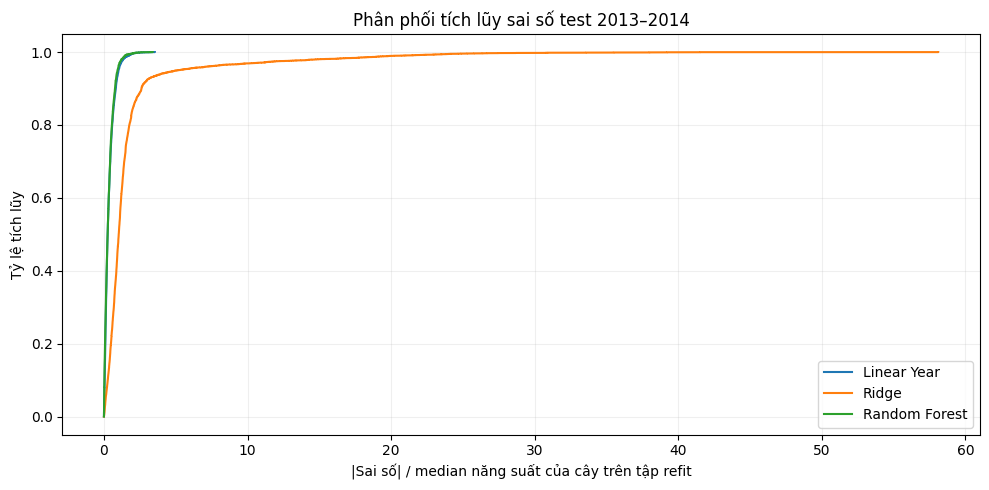

Nhận xét: Mô hình chọn bằng validation là Random Forest, có Macro_NMAE test 0.343. Đường ECDF cao hơn tại cùng ngưỡng sai số cho thấy nhiều bản ghi có sai số nằm dưới ngưỡng đó hơn.


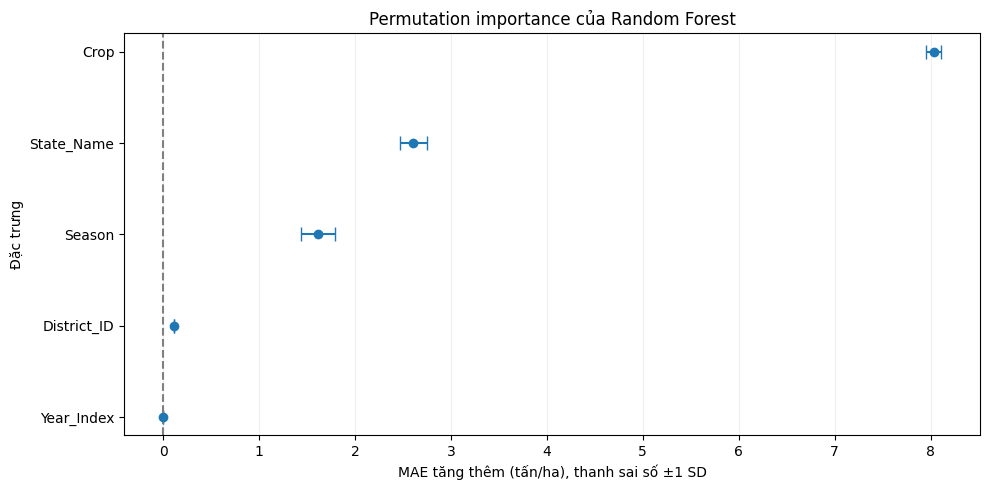

Nhận xét: Đặc trưng có importance trung bình lớn nhất là Crop: 8.032 tấn/ha MAE tăng thêm. Kết quả thể hiện sự phụ thuộc của mô hình, không chứng minh nhân quả; bang và huyện có thông tin liên quan.

Hoàn thành phần mô hình và đề xuất.
Mô hình được chọn: Random Forest
Số nhận xét biểu đồ: 13
Kết quả được lưu tại: /workspace/.cloud/model_agriculture/review_run_2a67a4d7/notebooks/outputs/output_03


In [8]:

# 17. HÀM LƯU BIỂU ĐỒ VÀ NHẬN XÉT


notes = []

def finish(filename, comment):
    plt.tight_layout()

    plt.savefig(
        FIG / filename,
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    notes.append({
        "File": filename,
        "Comment": comment
    })

    print("Nhận xét:", comment)

# BIỂU ĐỒ 7: ECDF SAI SỐ TEST


plt.figure(figsize=(10, 5))

for name in model_names:

    errors = np.sort(
        (
            np.abs(
                predictions["Yield"] - predictions[name]
            )
            / predictions["Crop"].map(scale_dev)
        ).to_numpy()
    )

    cumulative = (
        np.arange(1, len(errors) + 1)
        / len(errors)
    )

    plt.step(
        errors,
        cumulative,
        where="post",
        label=name
    )

plt.title("Phân phối tích lũy sai số test 2013–2014")
plt.xlabel(
    "|Sai số| / median năng suất của cây trên tập refit"
)
plt.ylabel("Tỷ lệ tích lũy")
plt.legend()
plt.grid(alpha=0.2)

selected_test = (
    metrics.set_index("Model")
    .loc[selected]
)

finish(
    "07_ecdf.png",
    f"Mô hình chọn bằng validation là {selected}, "
    f"có Macro_NMAE test "
    f"{selected_test['Macro_NMAE']:.3f}. "
    "Đường ECDF cao hơn tại cùng ngưỡng sai số cho thấy "
    "nhiều bản ghi có sai số nằm dưới ngưỡng đó hơn."
)

# BIỂU ĐỒ 8: DOT PLOT PERMUTATION IMPORTANCE


plt.figure(figsize=(10, 5))

plt.errorbar(
    importance["Importance"],
    importance["Feature"],
    xerr=importance["SD"],
    fmt="o",
    capsize=5
)

plt.axvline(
    0,
    color="gray",
    linestyle="--"
)

plt.title("Permutation importance của Random Forest")
plt.xlabel("MAE tăng thêm (tấn/ha), thanh sai số ±1 SD")
plt.ylabel("Đặc trưng")
plt.grid(axis="x", alpha=0.2)

top_feature = importance.iloc[-1]

finish(
    "08_importance.png",
    f"Đặc trưng có importance trung bình lớn nhất là "
    f"{top_feature['Feature']}: "
    f"{top_feature['Importance']:.3f} tấn/ha MAE tăng thêm. "
    "Kết quả thể hiện sự phụ thuộc của mô hình, "
    "không chứng minh nhân quả; bang và huyện "
    "có thông tin liên quan."
)

# 18. GỘP NHẬN XÉT CỦA BIỂU ĐỒ CHÍNH VÀ BỔ SUNG

OUT2 = OUT / "output_02"

analysis_notes = pd.read_csv(
    OUT2 / "figure_notes_analysis.csv"
)

# Hỗ trợ bảng nhận xét của notebook 02 cũ; phiên bản mới đã có File–Comment.
if "Comment" not in analysis_notes.columns:
    analysis_notes["Comment"] = (
        analysis_notes["Main_Finding"].fillna("")
        + " " + analysis_notes["Limitation"].fillna("")
    )
    analysis_notes["File"] = analysis_notes["File"].replace({
        "01_line.png": "02_line.png", "02_bar.png": "03_bar.png",
        "03_histogram.png": "04_histogram.png", "04_heatmap.png": "05_heatmap.png",
        "05_boxplot.png": "06_boxplot.png", "06_regression.png": "01_regression.png"
    })
all_notes = pd.concat(
    [
        analysis_notes[["File", "Comment"]],
        pd.DataFrame(notes)[["File", "Comment"]]
    ],
    ignore_index=True
)

assert all_notes["File"].is_unique, "Tên ảnh trong bảng nhận xét bị lặp"
assert all((FIG / name).is_file() for name in all_notes["File"])

all_notes.to_csv(
    OUT3 / "figure_notes.csv",
    index=False
)

# 19. LƯU THÔNG TIN CHO DASHBOARD

# Config cũ chưa có metadata mới: suy ra từ các CSV đã đọc, không cần huấn luyện lại.
actual_split_years = {
    name: [int(part["Crop_Year"].min()), int(part["Crop_Year"].max())]
    for name, part in [("Train", train), ("Validation", val), ("Test", test)]
}
time_ordered = (
    actual_split_years["Train"][1] < actual_split_years["Validation"][0]
    and actual_split_years["Validation"][1] < actual_split_years["Test"][0]
)
metadata_keys = ["split_strategy", "split_years", "model_scope_note", "states_without_test"]
missing_metadata = [key for key in metadata_keys if config.get(key) is None]
if missing_metadata:
    print("Config cũ thiếu metadata:", ", ".join(missing_metadata))
    print("Suy ra khoảng năm và độ phủ từ CSV hiện tại; không thay đổi dữ liệu/mô hình. "
          "Chạy lại notebook 02 mới để lưu đầy đủ config.")

model_info = {
    "selected_model": selected,
    "best_parameters": best_parameters,
    "states": STATES,
    "crops": CROPS,
    "train_n": len(train),
    "val_n": len(val),
    "test_n": len(test),
    "split_strategy": config.get("split_strategy") or ("time_based" if time_ordered else "unspecified"),
    "split_years": config.get("split_years") or actual_split_years,
    "scope_note": config.get("model_scope_note") or f"Phạm vi mô hình gồm {len(STATES)} bang trong model_states; không đại diện mọi địa bàn.",
    "states_without_test": config.get("states_without_test") if config.get("states_without_test") is not None else sorted(set(STATES) - set(test["State_Name"])),
    "recommendation_thresholds": THRESHOLDS,
    "test_states": sorted(
        test["State_Name"].unique().tolist()
    )
}

(OUT3 / "model_info.json").write_text(
    json.dumps(
        model_info,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

print("\nHoàn thành phần mô hình và đề xuất.")
print("Mô hình được chọn:", selected)
print("Số nhận xét biểu đồ:", len(all_notes))
print("Kết quả được lưu tại:", OUT3.resolve())